# Tutorial 08 · Trees, Ensembles and Support Vector Machines

**STAT / SDST 3612 · From axis-aligned splits and bagging to maximum-margin classifiers**

Tutor: Yinghao Zhu · yhzhu99@connect.hku.hk

Given two measurements, predict a binary label with a flexible nonlinear boundary. Compare a single decision tree, bagged and boosted ensembles, and support vector machines on the same training, validation and test split, then choose one model using validation evidence.

The same prediction can come from very different assumptions: a tree carves the plane into rectangles, bagging averages many unstable trees, boosting corrects errors in sequence, and an SVM chooses the widest separating street. Putting them on the same data makes their inductive biases, failure modes and validation choices concrete.

## Learning route

1. **Data: Two Moons and Iris Petals** — What makes a boundary nonlinear?
2. **A Single Decision Tree** — How does one tree carve up the plane?
3. **Bagging and Random Forests** — Why average many trees?
4. **Boosting: Learn from Mistakes** — How does a sequence of weak trees become strong?
5. **Support Vector Machines: The Widest Street** — Which separating line should we prefer?
6. **Kernels: Change the Geometry** — What if a straight line cannot separate the classes?
7. **Compare, Choose, Test** — Which model deserves the final test?

Follow the chapters in order. Each one connects the idea, a decision-boundary plot,
the Python operation and a small editable experiment. Model settings are chosen on
validation data; the shared test split is evaluated once at the end.

## Learning objectives

- Explain how a decision tree uses axis-aligned splits and how depth and leaf size control overfitting.
- Distinguish bagging from random forests, and interpret validation and out-of-bag evidence for ensemble size and feature randomness.
- Explain how AdaBoost and gradient boosting correct previous errors, and select a learning rate and number of trees using staged validation curves.
- Identify margins, support vectors and the role of C in a soft-margin SVM, and connect the geometry to hinge loss.
- Compare linear, polynomial and RBF kernels, explain the effect of gamma and degree, and recognize when a kernel is needed.
- Select a model on validation data, inspect its confusion matrix, and evaluate the frozen choice once on held-out test data.

**Prerequisites:** Basic Python and NumPy, plus binary classification, accuracy, precision and recall from lecture. No previous tree, ensemble or SVM implementation is required.

**Outcome:** An executed notebook with decision-boundary plots, validation comparisons for every model family, one inspected error case, and a justified final test result.

All data are generated locally with scikit-learn and NumPy: two moons, iris petals and
XOR quadrants. Nothing is downloaded. The test rows are deliberately absent from the
setup namespace used by the editable snippets and from all plots below.

## Setup

Keep `experiment.py` and `curriculum.json` beside this notebook, or extract the
complete student ZIP. Install `requirements.txt` first. The next cell imports the
shared scientific functions and creates the fixed train / validation / test split.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from experiment import (Experiment, metrics, make_teaching_data, build_tree, build_forest,
                        build_boosting, build_svm)

lab = Experiment()
X_train, y_train = lab.moons["X_train"].copy(), lab.moons["y_train"].copy()
X_val, y_val = lab.moons["X_val"].copy(), lab.moons["y_val"].copy()
X_iris_train, y_iris_train = lab.iris["X_train"].copy(), lab.iris["y_train"].copy()
X_iris_val, y_iris_val = lab.iris["X_val"].copy(), lab.iris["y_val"].copy()
X_xor_train, y_xor_train = lab.xor["X_train"].copy(), lab.xor["y_train"].copy()
X_xor_val, y_xor_val = lab.xor["X_val"].copy(), lab.xor["y_val"].copy()
initial = lab.initialize()
compare_models = lab.compare
plt.rcParams.update({"figure.figsize": (7, 4.8), "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE, ORANGE = "#45657e", "#aa613d"

def draw(plot, data, title):
    """Plot a decision surface, train/validation rows and optional support vectors."""
    bounds = plot["bounds"]
    fig, ax = plt.subplots()
    grid = plot.get("grid")
    if grid:
        z = np.asarray(grid["z"])
        ax.contourf(grid["x"], grid["y"], z, levels=np.linspace(-1, 1, 21),
                    cmap="RdBu_r", alpha=.35)
        ax.contour(grid["x"], grid["y"], z, levels=[0], colors="#202e3a", linewidths=1)
    for split, marker, size, alpha in (("train", "o", 18, .55), ("validation", "^", 32, .9)):
        rows = [point for point in plot["points"] if point["split"] == split]
        if rows:
            ax.scatter([p["x"] for p in rows], [p["y"] for p in rows],
                       c=[ORANGE if p["label"] else BLUE for p in rows],
                       marker=marker, s=size, alpha=alpha,
                       edgecolors="white" if split == "validation" else "none",
                       linewidths=.5, label=split)
    for point in plot.get("support", []):
        ax.scatter(point["x"], point["y"], s=95, facecolors="none",
                   edgecolors="#202e3a", linewidths=1.4)
    for line in plot.get("lines", []):
        ax.plot([line["x1"], line["x2"]], [line["y1"], line["y2"]], color="#202e3a",
                linestyle="--" if line.get("dashed") else "-", linewidth=1.4)
    ax.set_xlim(bounds[0], bounds[1])
    ax.set_ylim(bounds[2], bounds[3])
    ax.set_xlabel(data["feature_names"][0])
    ax.set_ylabel(data["feature_names"][1])
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()

## 1. Data: Two Moons and Iris Petals

### Two geometric problems, one fair split

A classifier learns from examples. Here each example has two measurements and a binary label; the boundary is what we want to see.

- The `two moons` set has 600 points arranged in two interleaving crescents. No straight line separates the classes, so a flexible boundary is necessary.
- The `iris petals` set uses 100 flowers from two species and two measurements: petal length and petal width. It gives a small, interpretable stage for a linear margin.
- We use a stratified 60% / 20% / 20% split with seed 3612. The test rows are hidden from the browser and from editable snippets.
- A model is fitted on training rows, compared on validation rows and tested once. The majority-class baseline is 50% on the balanced moon and iris splits.

### Formula and notation

$$\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{n},\qquad \mathbf{x}_i\in\mathbb{R}^{2},\qquad y_i\in\{0,1\}$$

- $\mathcal{D}$: The labelled dataset.
- $\mathbf{x}_i$: Two measured features for example i.
- $y_i$: The binary class: 0 or 1.

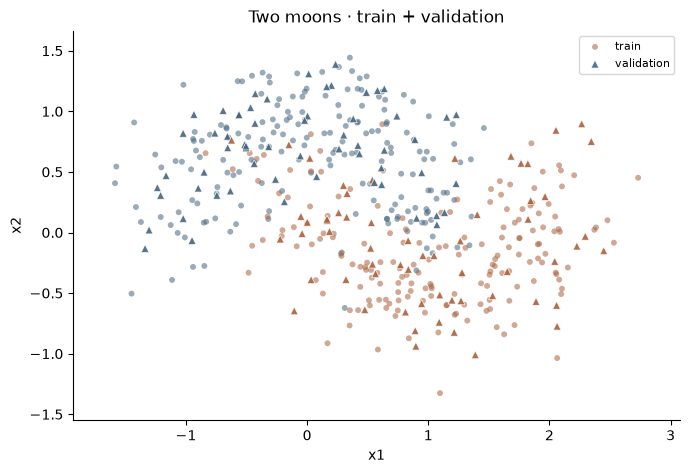

moons {'train': {'total': 360, 'class0': 180, 'class1': 180}, 'val': {'total': 120, 'class0': 60, 'class1': 60}, 'test': {'total': 120, 'class0': 60, 'class1': 60}}


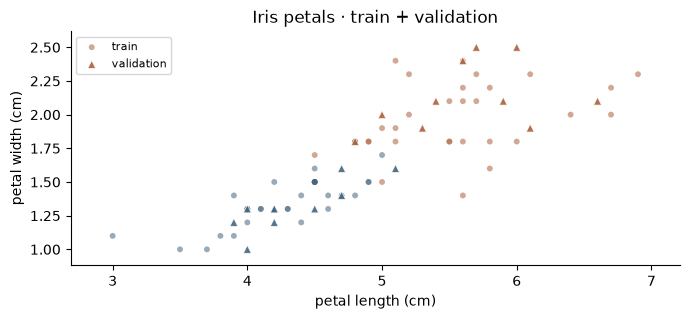

iris {'train': {'total': 60, 'class0': 30, 'class1': 30}, 'val': {'total': 20, 'class0': 10, 'class1': 10}, 'test': {'total': 20, 'class0': 10, 'class1': 10}}


In [2]:
for name in ("moons", "iris"):
    data = lab.datasets[name]
    draw(lab.data_plot(name), data, data["name"] + " · train + validation")
    print(name, initial["counts"][name])

### Inspect the data and the baseline

Compare the two scatter plots. Why would a single straight line struggle on two moons but work better on iris petals?

### Python: shapes, splits and a baseline

Run the example, change one input or choice, then explain the output.

In [3]:
print("Moons train / validation:", X_train.shape, X_val.shape)
print("Train labels:", np.bincount(y_train.astype(int)))
print("Validation labels:", np.bincount(y_val.astype(int)))
baseline = np.zeros(len(y_val), dtype=int)
print("Always-0 validation accuracy:", metrics(y_val, baseline)["accuracy"])
print("Iris train / validation:", X_iris_train.shape[0], X_iris_val.shape[0])
print("XOR train / validation:", X_xor_train.shape[0], X_xor_val.shape[0])

Moons train / validation: (360, 2) (120, 2)
Train labels: [180 180]
Validation labels: [60 60]
Always-0 validation accuracy: 0.5
Iris train / validation: 60 20
XOR train / validation: 240 80


## 2. A Single Decision Tree

### A tree asks a sequence of yes/no questions

A decision tree partitions the plane with axis-aligned splits. Each internal node tests one feature against a threshold; each leaf predicts a class.

- Each split chooses the feature and threshold that most reduce impurity on the training rows. Gini impurity is one common criterion; entropy is another.
- Depth and minimum leaf size control capacity. A deep tree can chase noisy points and produce a jagged boundary.
- Training accuracy usually increases with depth. Use validation accuracy to choose a tree that generalizes.
- Axis-aligned splits are interpretable, but diagonal or curved boundaries become stair-step approximations.

### Formula and notation

$$G(t)=1-\sum_{k=0}^{1}p_{k}^{2}(t)$$

- $t$: A candidate node in the tree.
- $p_k(t)$: Proportion of class k among training rows reaching node t.
- $G(t)$: Gini impurity; zero means the node is pure.

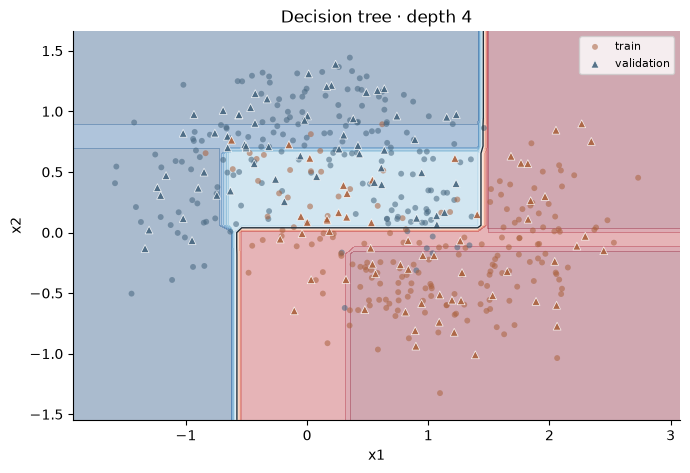

train {'accuracy': 0.9083333333333333, 'precision': 0.9622641509433962, 'recall': 0.85, 'f1': 0.9026548672566371, 'confusion': [[174, 6], [27, 153]]}
validation {'accuracy': 0.8583333333333333, 'precision': 1.0, 'recall': 0.7166666666666667, 'f1': 0.8349514563106796, 'confusion': [[60, 0], [17, 43]]}
leaves 10 actual depth 4


In [4]:
tree = build_tree(depth=4).fit(X_train, y_train)
draw(lab.plot_for(tree, lab.moons), lab.moons, "Decision tree · depth 4")
print("train", metrics(y_train, tree.predict(X_train)))
print("validation", metrics(y_val, tree.predict(X_val)))
print("leaves", tree.get_n_leaves(), "actual depth", tree.get_depth())

### Change the tree depth and watch the boundary

Start with depth 1. Increase depth and watch the boundary. When does training accuracy stop being a useful guide?

### Python: depth, training and validation

Run the example, change one input or choice, then explain the output.

In [5]:
for depth in (1, 2, 4, None):
    model = build_tree(depth=depth).fit(X_train, y_train)
    train = metrics(y_train, model.predict(X_train))["accuracy"]
    validation = metrics(y_val, model.predict(X_val))["accuracy"]
    print("depth", depth, "| train", round(train, 3), "| validation", round(validation, 3))

depth 1 | train 0.817 | validation 0.775
depth 2 | train 0.9 | validation 0.875
depth 4 | train 0.908 | validation 0.858
depth None | train 1.0 | validation 0.875


[scikit-learn decision trees](https://scikit-learn.org/stable/modules/tree.html)

## 3. Bagging and Random Forests

### Average many unstable trees

Bagging trains trees on bootstrap samples and averages their predictions. A random forest adds random feature subsets at each split to decorrelate the trees.

- Bagging draws rows with replacement. Each tree sees a different sample, so their errors are not identical.
- A random forest also considers only a random subset of features at each split. This prevents one dominant feature from making every tree nearly the same.
- Averaging reduces variance most when individual trees are strong but different. More trees stabilize predictions; gains eventually flatten.
- Out-of-bag rows are omitted from a tree's bootstrap sample. Their score is an internal estimate, not a replacement for the validation split.

### Formula and notation

$$\hat p_{\mathrm{bag}}(\mathbf{x})=\frac{1}{B}\sum_{b=1}^{B}\hat p_b(\mathbf{x})$$

- $B$: Number of trees in the ensemble.
- $\hat p_b(\mathbf{x})$: Class-1 probability from tree b.
- $\hat p_{\mathrm{bag}}$: Averaged probability used by the ensemble.

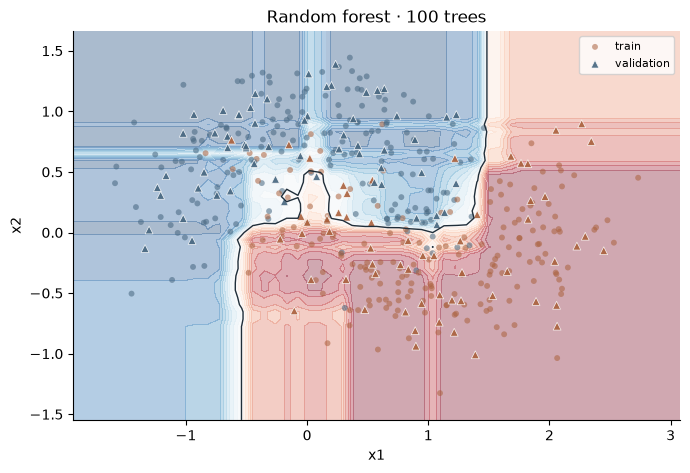

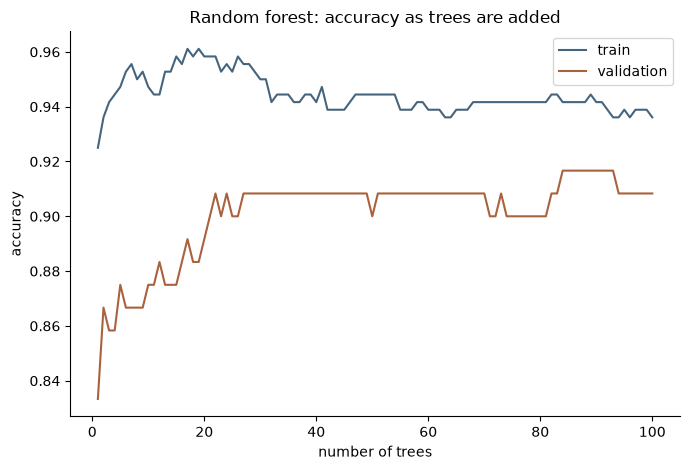

OOB 0.9055555555555556 validation {'accuracy': 0.9083333333333333, 'precision': 0.9803921568627451, 'recall': 0.8333333333333334, 'f1': 0.9009009009009009, 'confusion': [[59, 1], [10, 50]]}


In [6]:
row = lab.fit_forest({"mode": "forest", "n_estimators": 100})
draw(row["plot"], lab.moons, "Random forest · 100 trees")
curve = row["curve"]
plt.plot(curve["n"], curve["train"], color=BLUE, label="train")
plt.plot(curve["n"], curve["validation"], color=ORANGE, label="validation")
plt.xlabel("number of trees")
plt.ylabel("accuracy")
plt.title("Random forest: accuracy as trees are added")
plt.legend()
plt.tight_layout()
plt.show()
print("OOB", row["oob"], "validation", row["validation"])

### Compare bagging with a random forest

Compare bagging and the random forest at the same number of trees. Does feature randomness change validation accuracy, and how variable is the curve?

### Python: bagging, random forest and OOB

Run the example, change one input or choice, then explain the output.

In [7]:
for mode in ("bagging", "forest"):
    model = build_forest(mode=mode, n_estimators=100).fit(X_train, y_train)
    print(mode, "| OOB", round(model.oob_score_, 3),
          "| validation", round(metrics(y_val, model.predict(X_val))["accuracy"], 3))

bagging | OOB 0.9 | validation 0.883


forest | OOB 0.906 | validation 0.908


[scikit-learn ensembles](https://scikit-learn.org/stable/modules/ensemble.html)

## 4. Boosting: Learn from Mistakes

### Build a strong model from weak corrections

Boosting fits learners sequentially. AdaBoost increases the weight of misclassified rows; gradient boosting fits each new tree to the current errors.

- AdaBoost reweights training rows after each weak learner. Gradient boosting fits each new tree to the negative gradient of the loss.
- The learning rate scales each new tree's contribution. A smaller rate often needs more trees; too many trees can still overfit.
- A staged validation curve records accuracy after each added tree, so you can see when extra capacity stops helping.
- Boosting focuses on hard examples, which also makes it sensitive to label noise and outliers.
- Libraries such as XGBoost implement the same additive idea with additional regularization and engineering optimizations. This lesson uses scikit-learn's implementation so every example runs in the browser.

### Formula and notation

$$F_m(\mathbf{x})=F_{m-1}(\mathbf{x})+\nu\,h_m(\mathbf{x})$$

- $F_m$: The ensemble after m trees.
- $h_m$: The next weak learner fitted to the current errors.
- $\nu$: Learning rate, also called the shrinkage factor.

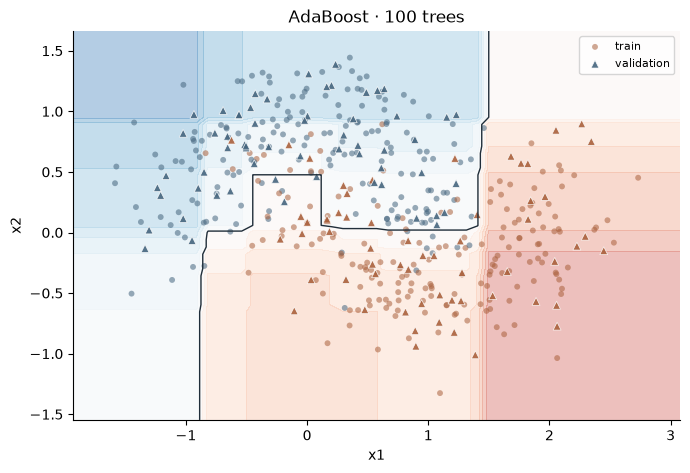

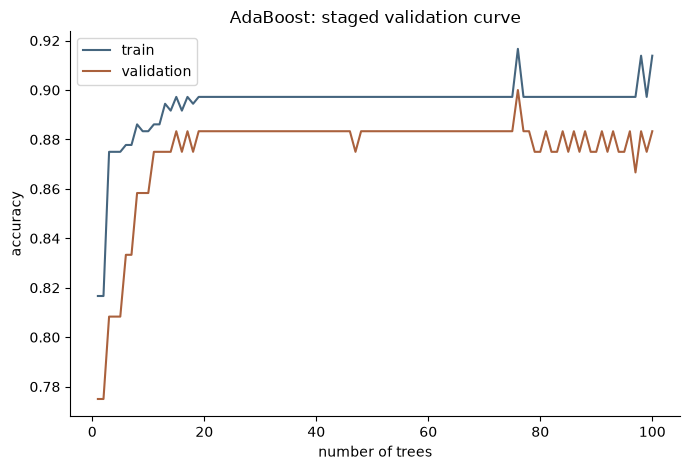

adaboost best staged tree 76 validation {'accuracy': 0.8833333333333333, 'precision': 0.9423076923076923, 'recall': 0.8166666666666667, 'f1': 0.8749999999999999, 'confusion': [[57, 3], [11, 49]]}


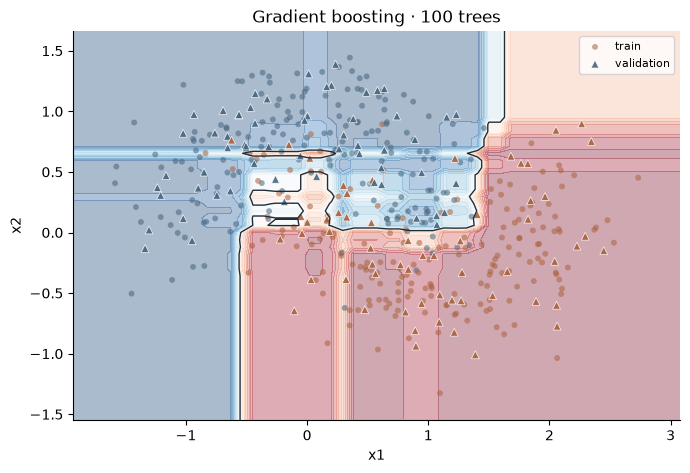

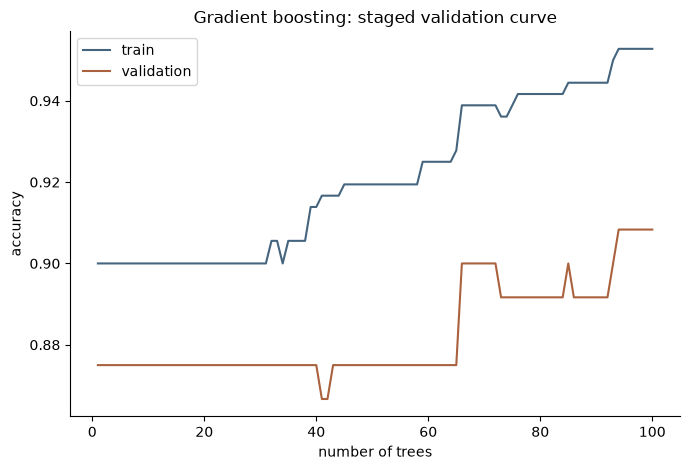

gradient best staged tree 94 validation {'accuracy': 0.9083333333333333, 'precision': 0.9803921568627451, 'recall': 0.8333333333333334, 'f1': 0.9009009009009009, 'confusion': [[59, 1], [10, 50]]}


In [8]:
for mode, lr in (("adaboost", .5), ("gradient", .1)):
    row = lab.fit_boosting({"mode": mode, "n_estimators": 100, "learning_rate": lr})
    draw(row["plot"], lab.moons, row["name"] + " · 100 trees")
    curve = row["curve"]
    plt.plot(curve["n"], curve["train"], color=BLUE, label="train")
    plt.plot(curve["n"], curve["validation"], color=ORANGE, label="validation")
    plt.xlabel("number of trees")
    plt.ylabel("accuracy")
    plt.title(row["name"] + ": staged validation curve")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(mode, "best staged tree", row["best_n"], "validation", row["validation"])

### Tune boosting on validation data

Hold the number of trees fixed and change the learning rate. Which setting reaches a good validation score with fewer trees?

### Python: AdaBoost and gradient boosting

Run the example, change one input or choice, then explain the output.

In [9]:
for lr in (0.05, 0.1, 0.5):
    model = build_boosting(mode="gradient", n_estimators=100, learning_rate=lr)
    model.fit(X_train, y_train)
    train = metrics(y_train, model.predict(X_train))["accuracy"]
    validation = metrics(y_val, model.predict(X_val))["accuracy"]
    print("learning rate", lr, "| train", round(train, 3), "| validation", round(validation, 3))

learning rate 0.05 | train 0.917 | validation 0.883
learning rate 0.1 | train 0.953 | validation 0.908
learning rate 0.5 | train 1.0 | validation 0.9


[scikit-learn gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)

## 5. Support Vector Machines: The Widest Street

### Among separating lines, prefer the widest street

A linear SVM chooses the separating hyperplane with the largest margin. Points on the margin or inside it are support vectors; they determine the boundary.

- The margin is the distance between the boundary and the nearest training points. Maximizing it is a geometric regularizer.
- Soft-margin SVM allows violations. C trades margin width against training errors: larger C permits fewer violations and usually a narrower margin.
- The hinge loss is zero beyond the margin and grows linearly for points inside it or on the wrong side.
- Support vectors are the training points that matter. Moving a non-support point slightly may leave the fitted boundary unchanged.

### Formula and notation

$$\min_{\mathbf{w},b,\boldsymbol{\xi}}\ \frac{1}{2}\|\mathbf{w}\|^2+C\sum_i\xi_i\quad\text{s.t.}\quad y_i(\mathbf{w}^\top\mathbf{x}_i+b)\ge1-\xi_i,\ \xi_i\ge0$$

- $\mathbf{w},b$: Weights and intercept of the separating line.
- $\xi_i$: Slack for how far point i violates the margin.
- $C$: Penalty for violations. Small C allows a wider, softer margin.

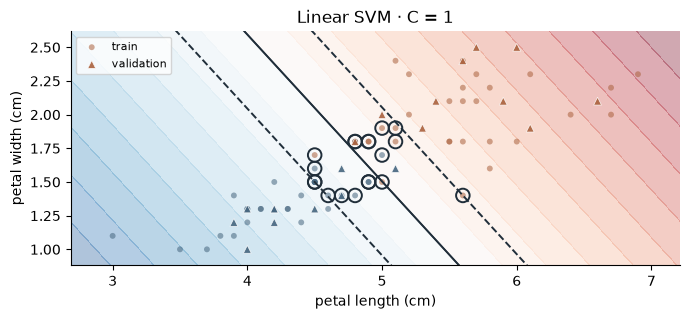

support vectors 19
train {'accuracy': 0.9333333333333333, 'precision': 0.9333333333333333, 'recall': 0.9333333333333333, 'f1': 0.9333333333333333, 'confusion': [[28, 2], [2, 28]]}
validation {'accuracy': 0.95, 'precision': 0.9090909090909091, 'recall': 1.0, 'f1': 0.9523809523809523, 'confusion': [[9, 1], [0, 10]]}


In [10]:
row = lab.fit_margin({"C": 1})
draw(row["plot"], lab.iris, "Linear SVM · C = 1")
print("support vectors", row["support_count"])
print("train", row["train"])
print("validation", row["validation"])

### Move the margin with C

Move C from small to large. What happens to the margin, the number of support vectors, and validation accuracy?

### Python: support vectors and the C setting

Run the example, change one input or choice, then explain the output.

In [11]:
for C in (0.01, 0.1, 1, 10):
    model = build_svm(kernel="linear", C=C).fit(X_iris_train, y_iris_train)
    train = metrics(y_iris_train, model.predict(X_iris_train))["accuracy"]
    validation = metrics(y_iris_val, model.predict(X_iris_val))["accuracy"]
    print("C", C, "| support vectors", len(model.support_),
          "| train", round(train, 3), "| validation", round(validation, 3))

C 0.01 | support vectors 60 | train 0.9 | validation 0.9
C 0.1 | support vectors 36 | train 0.933 | validation 0.9
C 1 | support vectors 19 | train 0.933 | validation 0.95
C 10 | support vectors 12 | train 0.933 | validation 0.95


[scikit-learn support vector machines](https://scikit-learn.org/stable/modules/svm.html)

## 6. Kernels: Change the Geometry

### Kernels let a linear boundary act in a richer space

A kernel computes an inner product in a transformed feature space without explicitly building that space. Polynomial and RBF kernels produce curved boundaries in the original plane.

- Linear: `K(x,z)=x·z`. Polynomial: `K(x,z)=(γ x·z+r)^d`. RBF: `K(x,z)=exp(-γ||x-z||²)`.
- Gamma controls the reach of each point: small gamma gives smooth, broad boundaries; large gamma gives local, wiggly ones.
- The kernel trick replaces dot products; the SVM still solves the same convex optimization problem.
- XOR has no useful linear split. A linear SVM fails; an RBF kernel can separate the quadrants.

### Formula and notation

$$K_{\mathrm{RBF}}(\mathbf{x},\mathbf{z})=\exp\!\left(-\gamma\|\mathbf{x}-\mathbf{z}\|^2\right)$$

- $K(\mathbf{x},\mathbf{z})$: Kernel similarity between two examples.
- $\gamma$: RBF reach: larger values make each point's influence more local.
- $d$: Polynomial degree: larger values add higher-order interactions.

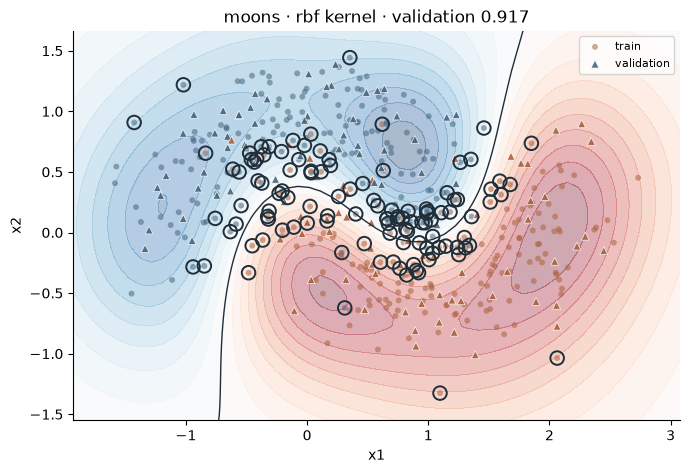

moons rbf support vectors 114 validation {'accuracy': 0.9166666666666666, 'precision': 0.9807692307692307, 'recall': 0.85, 'f1': 0.9107142857142857, 'confusion': [[59, 1], [9, 51]]}


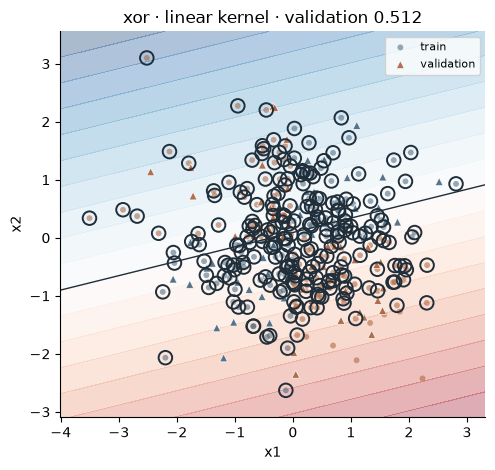

xor linear support vectors 233 validation {'accuracy': 0.5125, 'precision': 0.5217391304347826, 'recall': 0.5853658536585366, 'f1': 0.5517241379310345, 'confusion': [[17, 22], [17, 24]]}


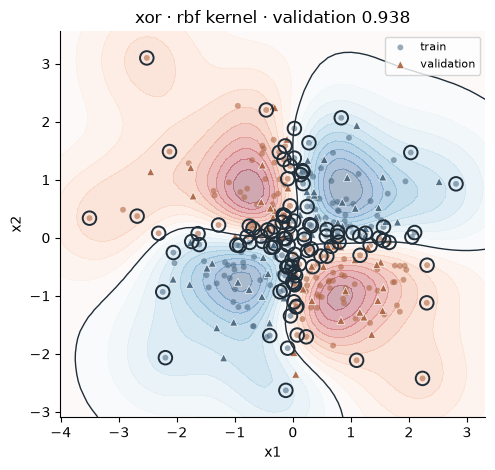

xor rbf support vectors 108 validation {'accuracy': 0.9375, 'precision': 0.9736842105263158, 'recall': 0.9024390243902439, 'f1': 0.9367088607594938, 'confusion': [[38, 1], [4, 37]]}


In [12]:
for dataset, kernel, gamma in (("moons", "rbf", 1), ("xor", "linear", 1),
                                ("xor", "rbf", 1)):
    row = lab.fit_kernel({"dataset": dataset, "kernel": kernel, "C": 1,
                          "gamma": gamma, "degree": 3})
    draw(row["plot"], lab.datasets[dataset],
         f"{dataset} · {kernel} kernel · validation {row['validation']['accuracy']:.3f}")
    print(dataset, kernel, "support vectors", row["support_count"],
          "validation", row["validation"])

### Compare kernels on two moons and XOR

Switch between moons and XOR. Which kernel can bend enough for each dataset? What does a very large gamma do?

### Python: linear, polynomial and RBF kernels

Run the example, change one input or choice, then explain the output.

In [13]:
for kernel in ("linear", "poly", "rbf"):
    model = build_svm(kernel=kernel, C=1, gamma=1, degree=3)
    model.fit(X_train, y_train)
    validation = metrics(y_val, model.predict(X_val))["accuracy"]
    print(kernel, "| support vectors", len(model.support_),
          "| validation", round(validation, 3))
for kernel in ("linear", "rbf"):
    model = build_svm(kernel=kernel, C=1, gamma=1).fit(X_xor_train, y_xor_train)
    print("XOR", kernel, "| validation", round(metrics(y_xor_val, model.predict(X_xor_val))["accuracy"], 3))

linear | support vectors 140 | validation 0.817
poly | support vectors 146 | validation 0.792
rbf | support vectors 114 | validation 0.917
XOR linear | validation 0.512
XOR rbf | validation 0.938


[scikit-learn kernel SVM](https://scikit-learn.org/stable/modules/svm.html#kernel-functions)

## 7. Compare, Choose, Test

### Validation chooses; test reports

Each family has a different inductive bias. Compare their validation performance and errors, choose one, and evaluate it once on the test split.

- Every candidate uses the same training rows and the same validation rows. Changing the split changes the comparison.
- Validation accuracy is a starting point. Inspect the confusion matrix and individual errors before choosing.
- A more flexible model can win on training data and lose on validation. The test set does not help you choose.
- Record a reason before the final test. Once evaluated, the test decision is frozen.

### Formula and notation

$$m^{\star}=\arg\max_{m}\ \mathrm{Acc}_{\mathrm{val}}(m)$$

- $m$: One candidate model and its fitted settings.
- $\mathrm{Acc}_{\mathrm{val}}$: Accuracy on the validation rows.
- $m^{\star}$: The candidate selected before seeing test results.

RBF SVM · C = 1, γ = 1         train 0.906  validation 0.917  f1 0.911
Random forest · 160 trees      train 0.936  validation 0.908  f1 0.901
Gradient boosting · 120 trees  train 0.967  validation 0.908  f1 0.903
Bagged trees · 160 trees       train 0.947  validation 0.900  f1 0.895
AdaBoost · 120 stumps          train 0.914  validation 0.883  f1 0.875
Decision tree · depth 4        train 0.908  validation 0.858  f1 0.835
Linear SVM · C = 1             train 0.828  validation 0.817  f1 0.796
Selected on validation: RBF SVM · C = 1, γ = 1
{'accuracy': 0.9166666666666666, 'precision': 0.9807692307692307, 'recall': 0.85, 'f1': 0.9107142857142857, 'confusion': [[59, 1], [9, 51]]}


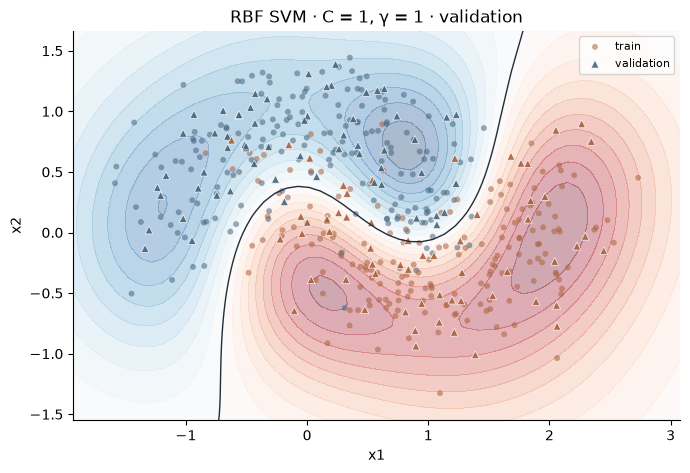

In [14]:
comparison = lab.compare()
rows = comparison["rows"]
for row in rows:
    print(f"{row['name']:<30} train {row['train']['accuracy']:.3f}  "
          f"validation {row['validation']['accuracy']:.3f}  f1 {row['validation']['f1']:.3f}")
selected = rows[0]
selected_key = selected["params"]["key"]
detail = lab.inspect_candidate({"key": selected_key})
print("Selected on validation:", detail["row"]["name"])
print(detail["metrics"])
draw(detail["plot"], lab.moons, detail["row"]["name"] + " · validation")

### Select on validation and evaluate test once

Inspect the validation table and at least one confusion matrix. Choose a model for a reason other than 'it is first'.

### Python: compare candidates and freeze a choice

Run the example, change one input or choice, then explain the output.

In [15]:
rows = compare_models()["rows"]
for row in rows:
    print(row["name"], "| validation", round(row["validation"]["accuracy"], 3))
best = max(rows, key=lambda row: row["validation"]["accuracy"])
print("Selected on validation:", best["name"])
print("Write a reason before running the final test cell.")

RBF SVM · C = 1, γ = 1 | validation 0.917
Random forest · 160 trees | validation 0.908
Gradient boosting · 120 trees | validation 0.908
Bagged trees · 160 trees | validation 0.9
AdaBoost · 120 stumps | validation 0.883
Decision tree · depth 4 | validation 0.858
Linear SVM · C = 1 | validation 0.817
Selected on validation: RBF SVM · C = 1, γ = 1
Write a reason before running the final test cell.


## Freeze a choice and evaluate the test set

Write a model-selection reason using validation evidence: performance, a confusion
matrix or an error pattern, and one limitation. The final test cell remains inactive
while the reason is empty. After it runs, the decision is frozen; restart the notebook
to begin a genuinely new experiment.

In [16]:
reason = ''  # Write your model and threshold rationale before testing.
if reason.strip():
    final = lab.final_test({"key": selected_key, "reason": reason})
    print(json.dumps(final, indent=2))
else:
    print("Record a rationale above, then run the final test once.")

Record a rationale above, then run the final test once.


## Your experiment record

Report the data split, one decision-boundary plot, validation comparisons for the
tree, forest, boosting and SVM families, one inspected error case, and the final
validation/test result. Explain why the selected model is appropriate and what the
result does not establish.

In [17]:
record = {"seed": initial["seed"], "counts": initial["counts"],
          "comparison": comparison["rows"], "final": lab.final}
Path("tutorial08-results.json").write_text(json.dumps(record, indent=2))
print("Recorded candidates:", len(record["comparison"]))

Recorded candidates: 7


## Appendix: supporting scientific functions

The lesson above uses the public helpers directly. These functions are copied from
`experiment.py` for readers who want to inspect or modify data generation, metrics,
model builders and plotting payloads. They are not prerequisites for following the
lesson.

In [18]:
import numpy as np
from sklearn.datasets import load_iris, make_moons
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier,
                              GradientBoostingClassifier, RandomForestClassifier)
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text
from experiment import SEED

### `split_dataset`

In [19]:
def split_dataset(X, y):
    """Return deterministic, stratified 60 / 20 / 20 train / validation / test rows."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=.2, stratify=y, random_state=SEED)
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=.25, stratify=y_dev, random_state=SEED)
    return {'X_train': X_train, 'y_train': y_train, 'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test}

### `make_teaching_data`

In [20]:
def make_teaching_data():
    """Create the three fixed datasets used by both the lesson and the notebook."""
    X, y = make_moons(n_samples=600, noise=.30, random_state=SEED)
    moons = split_dataset(X, y)
    moons['name'] = 'Two moons'
    moons['feature_names'] = ['x1', 'x2']

    iris = load_iris()
    keep = np.isin(iris.target, [1, 2])
    # 0 = versicolor, 1 = virginica. Raw petal measurements keep the margin readable.
    X_iris = iris.data[keep][:, [2, 3]]
    y_iris = (iris.target[keep] == 2).astype(int)
    iris_data = split_dataset(X_iris, y_iris)
    iris_data['name'] = 'Iris petals'
    iris_data['feature_names'] = ['petal length (cm)', 'petal width (cm)']

    rng = np.random.default_rng(SEED)
    X_xor = rng.normal(size=(400, 2))
    y_xor = np.logical_xor(X_xor[:, 0] > 0, X_xor[:, 1] > 0).astype(int)
    xor = split_dataset(X_xor, y_xor)
    xor['name'] = 'XOR quadrants'
    xor['feature_names'] = ['x1', 'x2']
    return {'moons': moons, 'iris': iris_data, 'xor': xor}

### `metrics`

In [21]:
def metrics(y_true, y_pred):
    """Decision metrics for a binary task; class 1 is the positive class."""
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.
    recall = tp / (tp + fn) if tp + fn else 0.
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.
    return {'accuracy': float((y_true == y_pred).mean()),
            'precision': float(precision), 'recall': float(recall), 'f1': float(f1),
            'confusion': [[int(tn), int(fp)], [int(fn), int(tp)]]}

### `build_tree`

In [22]:
def build_tree(depth=4, min_leaf=1):
    """A single axis-aligned classification tree."""
    depth = None if depth in (None, 'None', 0, '0') else int(depth)
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=max(1, int(min_leaf)),
                                  random_state=SEED)

### `build_forest`

In [23]:
def build_forest(mode='forest', n_estimators=100, max_features='sqrt', max_depth=6):
    """Bagged trees (``mode='bagging'``) or a random forest (``mode='forest'``)."""
    n_estimators = max(1, int(n_estimators))
    max_depth = None if max_depth in (None, 'None', 0) else int(max_depth)
    if mode == 'bagging':
        return BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=max_depth, random_state=SEED),
            n_estimators=n_estimators, max_samples=1.0, bootstrap=True,
            oob_score=True, n_jobs=1, random_state=SEED)
    if mode != 'forest':
        raise ValueError('mode must be forest or bagging')
    features = 1.0 if max_features in ('all', 1.0, '1.0') else max_features
    return RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth, max_features=features,
        bootstrap=True, oob_score=True, n_jobs=1, random_state=SEED)

### `build_boosting`

In [24]:
def build_boosting(mode='gradient', n_estimators=100, learning_rate=.1):
    """AdaBoost with stumps or gradient-boosted shallow trees."""
    n_estimators = max(1, int(n_estimators))
    learning_rate = float(learning_rate)
    if mode == 'adaboost':
        return AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
            n_estimators=n_estimators, learning_rate=learning_rate, random_state=SEED)
    if mode != 'gradient':
        raise ValueError('mode must be adaboost or gradient')
    return GradientBoostingClassifier(
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=2,
        random_state=SEED)

### `build_svm`

In [25]:
def build_svm(kernel='rbf', C=1., gamma=1., degree=3):
    """Soft-margin support vector classifier with one of three teaching kernels."""
    C = float(C)
    if C <= 0:
        raise ValueError('C must be positive.')
    if kernel == 'linear':
        return SVC(kernel='linear', C=C)
    if kernel not in ('poly', 'rbf', 'sigmoid'):
        raise ValueError('kernel must be linear, poly, rbf or sigmoid')
    return SVC(kernel=kernel, C=C, gamma=float(gamma), degree=int(degree))

### `_tree_probability`

In [26]:
def _tree_probability(estimator, X):
    """Read class-1 probability even when a bootstrap tree sees only one class."""
    probabilities = estimator.predict_proba(X)
    positive = np.zeros(len(X), dtype=float)
    for column, label in enumerate(estimator.classes_):
        if int(label) == 1:
            positive = probabilities[:, column]
    return positive

### `_bounds`

In [27]:
def _bounds(X):
    X = np.asarray(X, dtype=float)
    low, high = X.min(axis=0), X.max(axis=0)
    span = np.maximum(high - low, 1e-6)
    return [float(low[0] - .08 * span[0]), float(high[0] + .08 * span[0]),
            float(low[1] - .08 * span[1]), float(high[1] + .08 * span[1])]

### `_data_bounds`

In [28]:
def _data_bounds(data):
    return _bounds(np.vstack([data['X_train'], data['X_val']]))

### `_points`

In [29]:
def _points(X, y, split):
    return [{'x': float(x), 'y': float(z), 'label': int(label), 'split': split}
            for (x, z), label in zip(X, y)]

### `_importance`

In [30]:
def _importance(model):
    if hasattr(model, 'feature_importances_'):
        values = model.feature_importances_
    elif hasattr(model, 'estimators_'):
        values = np.mean([tree.feature_importances_ for tree in model.estimators_], axis=0)
    else:
        return []
    return [float(v) for v in values]

### `_grid`

In [31]:
def _grid(model, bounds, resolution=55):
    x = np.linspace(bounds[0], bounds[1], resolution)
    y = np.linspace(bounds[2], bounds[3], resolution)
    xx, yy = np.meshgrid(x, y)
    flat = np.column_stack([xx.ravel(), yy.ravel()])
    if hasattr(model, 'predict_proba'):
        z = 2 * model.predict_proba(flat)[:, 1] - 1
    else:
        z = model.decision_function(flat)
        scale = float(np.max(np.abs(z))) or 1.
        z = z / scale
    return {'x': x.tolist(), 'y': y.tolist(),
            'z': np.asarray(z).reshape(resolution, resolution).tolist()}

### `_support`

In [32]:
def _support(model, data):
    if not hasattr(model, 'support_'):
        return []
    return [{'x': float(x[0]), 'y': float(x[1]), 'label': int(data['y_train'][i])}
            for i, x in zip(model.support_, model.support_vectors_)]

### `_margin_lines`

In [33]:
def _margin_lines(model, bounds):
    """Return f=0 and f=±1 lines for a linear SVC, clipped to the plot bounds."""
    if not hasattr(model, 'coef_'):
        return []
    w, b = model.coef_[0], float(model.intercept_[0])
    lines = []
    for level, name, dashed in ((0., 'boundary f=0', False),
                                (1., 'margin f=+1', True),
                                (-1., 'margin f=-1', True)):
        if abs(w[1]) > 1e-9:
            x1, x2 = bounds[0], bounds[1]
            y1 = (level - b - w[0] * x1) / w[1]
            y2 = (level - b - w[0] * x2) / w[1]
        elif abs(w[0]) > 1e-9:
            x1 = x2 = (level - b) / w[0]
            y1, y2 = bounds[2], bounds[3]
        else:
            continue
        lines.append({'name': name, 'x1': float(x1), 'y1': float(y1),
                      'x2': float(x2), 'y2': float(y2), 'dashed': dashed})
    return lines